In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score,classification_report, confusion_matrix,ConfusionMatrixDisplay,f1_score)

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('winequality-red.csv', sep=';')

In [ ]:
df.shape

(1599, 1)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [ ]:
df.duplicated().sum()

np.int64(240)

In [ ]:
df.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [ ]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

In [ ]:
df.dtypes

,0
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


In [ ]:
missing_percentage=df.isnull().sum()/len(df)*100
print('missing_percentage')

missing_percentage


#Check dataset size

In [ ]:
df.shape[0]
df.shape[1]

12

#Average Values

In [ ]:
print('AVERAGE ACIDITY:',df['fixed acidity'].mean())
print('AVERAGE VOLATILE ACIDITY:',df['volatile acidity'].mean())
print('AVERAGE CITES:',df['citric acid'].mean())
print('AVERAGE RESIDUAL SUGAR:',df['residual sugar'].mean())
print('AVERAGE CHLORIDES:',df['chlorides'].mean())

AVERAGE ACIDITY: 8.31963727329581
AVERAGE VOLATILE ACIDITY: 0.5278205128205128
AVERAGE CITES: 0.2709756097560976
AVERAGE RESIDUAL SUGAR: 2.53880550343965
AVERAGE CHLORIDES: 0.08746654158849279


#most common quality score

In [ ]:
df['quality'].value_counts().sort_index()

,count
quality,
3,10
4,53
5,681
6,638
7,199
8,18


# most frequent score

In [ ]:
df["quality"].mode()

,quality
0,5


#alcohol content

In [ ]:
df.groupby ('quality') ['alcohol'].mean()

,alcohol
quality,
3,9.955000
4,10.265094
5,9.899706
6,10.629519
7,11.465913
8,12.094444


# acidity

In [ ]:
df.groupby ('quality') ['fixed acidity'].mean()

,fixed acidity
quality,
3,8.360000
4,7.779245
5,8.167254
6,8.347179
7,8.872362
8,8.566667


#Correlation

In [ ]:
df.corr(numeric_only=True)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
fixed acidity,1.000000,-0.256131,0.671703,0.114777,0.093705,-0.153794,-0.113181,0.668047,-0.682978,0.183006,-0.061668,0.124052
volatile acidity,-0.256131,1.000000,-0.552496,0.001918,0.061298,-0.010504,0.076470,0.022026,0.234937,-0.260987,-0.202288,-0.390558
citric acid,0.671703,-0.552496,1.000000,0.143577,0.203823,-0.060978,0.035533,0.364947,-0.541904,0.312770,0.109903,0.226373
residual sugar,0.114777,0.001918,0.143577,1.000000,0.055610,0.187049,0.203028,0.355283,-0.085652,0.005527,0.042075,0.013732
chlorides,0.093705,0.061298,0.203823,0.055610,1.000000,0.005562,0.047400,0.200632,-0.265026,0.371260,-0.221141,-0.128907
free sulfur dioxide,-0.153794,-0.010504,-0.060978,0.187049,0.005562,1.000000,0.667666,-0.021946,0.070377,0.051658,-0.069408,-0.050656
total sulfur dioxide,-0.113181,0.076470,0.035533,0.203028,0.047400,0.667666,1.000000,0.071269,-0.066495,0.042947,-0.205654,-0.185100
density,0.668047,0.022026,0.364947,0.355283,0.200632,-0.021946,0.071269,1.000000,-0.341699,0.148506,-0.496180,-0.174919
pH,-0.682978,0.234937,-0.541904,-0.085652,-0.265026,0.070377,-0.066495,-0.341699,1.000000,-0.196648,0.205633,-0.057731
sulphates,0.183006,-0.260987,0.312770,0.005527,0.371260,0.051658,0.042947,0.148506,-0.196648,1.000000,0.093595,0.251397


#Data Validation

#Quality distribution Countplo

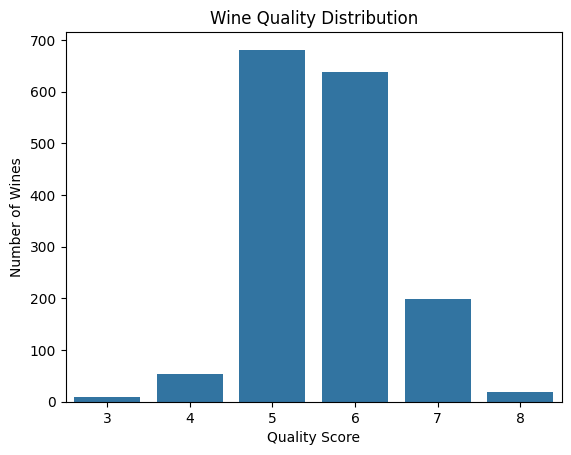

In [ ]:
sns.countplot(data=df, x='quality')

plt.title('Wine Quality Distribution')
plt.xlabel('Quality Score')
plt.ylabel('Number of Wines')
plt.show()

#Alcohol distribution Histogram

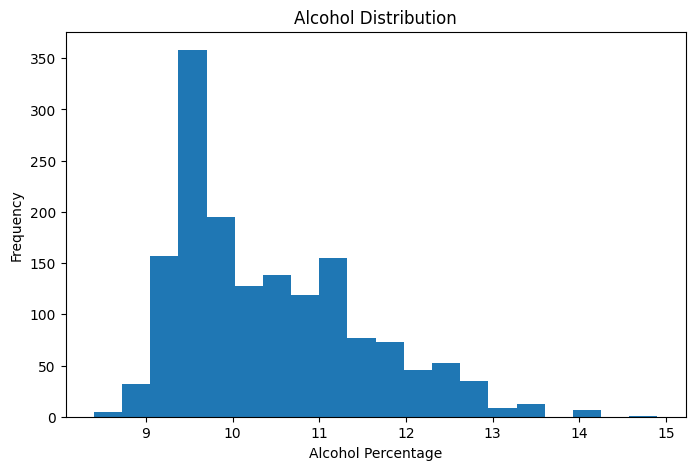

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(df['alcohol'], bins=20)
plt.title('Alcohol Distribution')
plt.xlabel('Alcohol Percentage')
plt.ylabel('Frequency')
plt.show()

#Alcohol vs Quality Boxplot

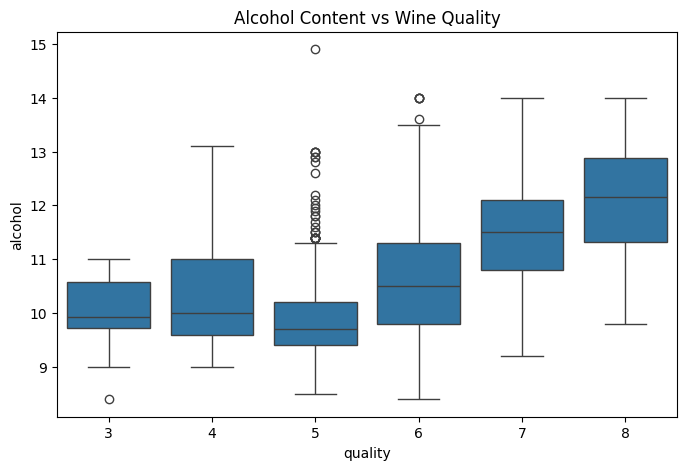

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='quality', y='alcohol')
plt.title('Alcohol Content vs Wine Quality')
plt.show()

#Correlation heatmap

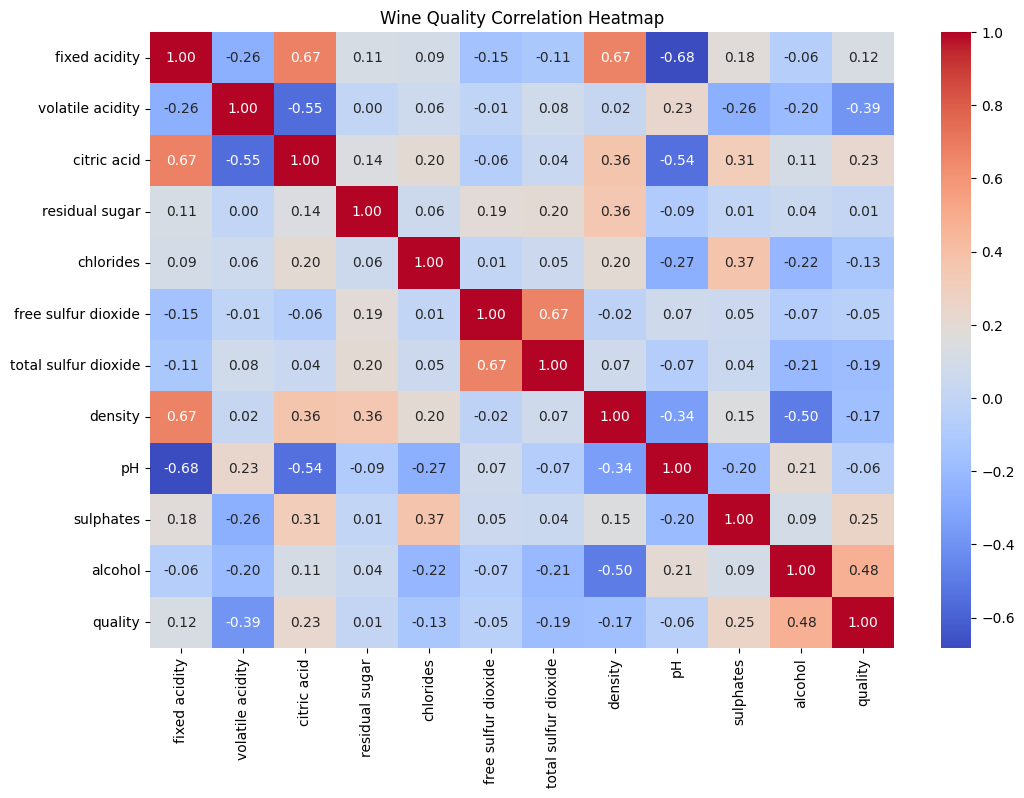

In [ ]:
plt.figure(figsize=(12,8))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f')
plt.title('Wine Quality Correlation Heatmap')
plt.show()

# Alcohol vs Quality Scatterplot

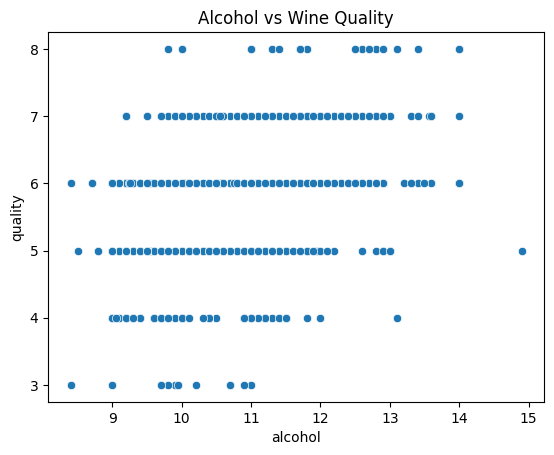

In [ ]:
sns.scatterplot(
    data=df,
    x='alcohol',
    y='quality')
plt.title('Alcohol vs Wine Quality')
plt.show()

#Feature selection

Feature selection means identifying useful input columns for predicting wine quality.
dataset has:
11 independent variables (X).
1 dependent variable (y)

In [ ]:
X = df.drop('quality', axis=1)
y = df['quality']

#correlation with quality

In [ ]:
correlation = df.corr(numeric_only=True)['quality']
print(correlation.sort_values(ascending=False))

quality                 1.000000
alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64


#importance using Random Forest

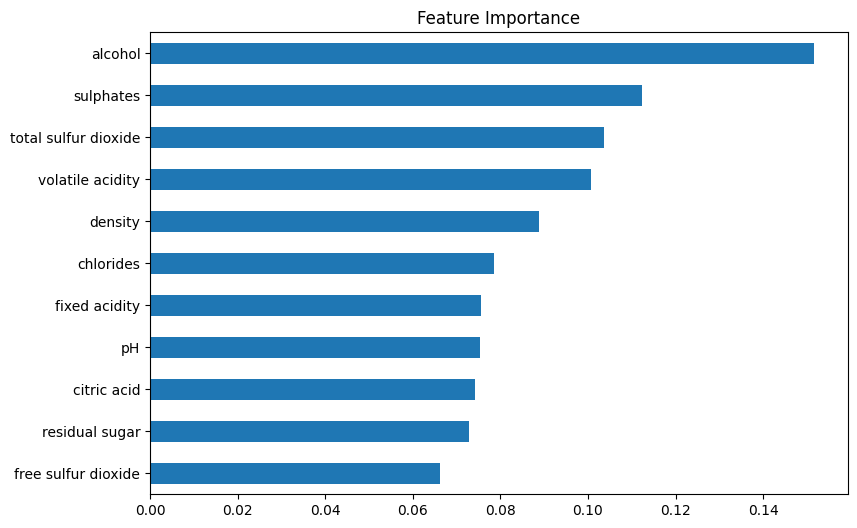

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(
n_estimators=100,
random_state=42)
rf.fit(X, y)
importance = pd.Series(
rf.feature_importances_,
index=X.columns)
importance.sort_values().plot(
kind='barh',
figsize=(9,6))
plt.title('Feature Importance')
plt.show()

#Machine Learning Models

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC

#Split the dataset


We divide our dataset into training and testing data.
- 80% training data.
- 20% testing data.

In [ ]:
X = df.drop('quality', axis=1)
y = df['quality']
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y)

#Train Random Forest

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42)
rf_model.fit(X_train, y_train)
rf_prediction = rf_model.predict(X_test)

#Train SGD Classifier

In [ ]:
sgd_model = make_pipeline(StandardScaler(),SGDClassifier(random_state=42, max_iter=2000))
sgd_model.fit(X_train, y_train)
sgd_prediction = sgd_model.predict(X_test)

#Train SVC Classifier

In [ ]:
svc_model = make_pipeline(StandardScaler(),SVC(kernel='rbf'))
svc_model.fit(X_train, y_train)
svc_prediction = svc_model.predict(X_test)

#Model evaluation and comparison

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix)

#Calculate aacuracy

In [ ]:
print("Random Forest:", accuracy_score(y_test, rf_prediction))
print("SGD:", accuracy_score(y_test, sgd_prediction))
print("SVC:", accuracy_score(y_test, svc_prediction))

Random Forest: 0.678125
SGD: 0.5125
SVC: 0.625


#Generate classification reports

In [ ]:
print("RANDOM FOREST REPORT")
print(classification_report(y_test, rf_prediction, zero_division=0))

RANDOM FOREST REPORT
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.71      0.76      0.73       136
           6       0.65      0.70      0.67       128
           7       0.71      0.55      0.62        40
           8       0.50      0.33      0.40         3

    accuracy                           0.68       320
   macro avg       0.43      0.39      0.40       320
weighted avg       0.65      0.68      0.66       320



#Repeat SGD and SVC

In [ ]:
print(classification_report(y_test, sgd_prediction, zero_division=0))
print(classification_report(y_test, svc_prediction, zero_division=0))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.57      0.76      0.66       136
           6       0.51      0.28      0.36       128
           7       0.39      0.60      0.48        40
           8       0.00      0.00      0.00         3

    accuracy                           0.51       320
   macro avg       0.25      0.27      0.25       320
weighted avg       0.50      0.51      0.48       320

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.65      0.76      0.70       136
           6       0.58      0.65      0.61       128
           7       0.78      0.35      0.48        40
           8       0.00      0.00      0.00         3

    accuracy                           0.62       320
   macro avg       0.33

#model comparison table

In [ ]:
results = pd.DataFrame({
    'Model': ['Random Forest', 'SGD', 'SVC'],
    'Accuracy': [
        accuracy_score(y_test, rf_prediction),
        accuracy_score(y_test, sgd_prediction),
        accuracy_score(y_test, svc_prediction)
    ],
    'Precision': [
        precision_score(y_test, rf_prediction, average='weighted', zero_division=0),
        precision_score(y_test, sgd_prediction, average='weighted', zero_division=0),
        precision_score(y_test, svc_prediction, average='weighted', zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, rf_prediction, average='weighted', zero_division=0),
        recall_score(y_test, sgd_prediction, average='weighted', zero_division=0),
        recall_score(y_test, svc_prediction, average='weighted', zero_division=0)
    ],
    'F1 Score': [
        f1_score(y_test, rf_prediction, average='weighted', zero_division=0),
        f1_score(y_test, sgd_prediction, average='weighted', zero_division=0),
        f1_score(y_test, svc_prediction, average='weighted', zero_division=0)
    ],
    'Macro F1': [
        f1_score(y_test, rf_prediction, average='macro', zero_division=0),
        f1_score(y_test, sgd_prediction, average='macro', zero_division=0),
        f1_score(y_test, svc_prediction, average='macro', zero_division=0)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score,Macro F1
0,Random Forest,0.678125,0.653070,0.678125,0.663245,0.404810
1,SGD,0.512500,0.499094,0.512500,0.483725,0.249173
2,SVC,0.625000,0.604835,0.625000,0.602252,0.298956


#Visualize model comparison

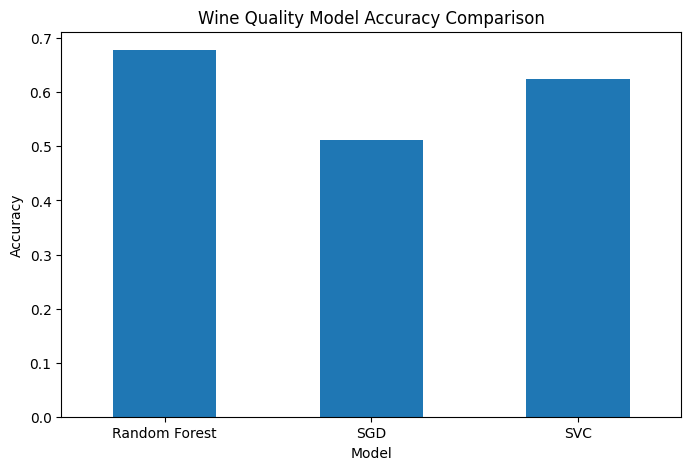

In [ ]:
results.set_index('Model')['Accuracy'].plot(
    kind='bar',
    figsize=(8,5))
plt.title('Wine Quality Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.xticks(rotation=0)
plt.show()

#Confusion matrix

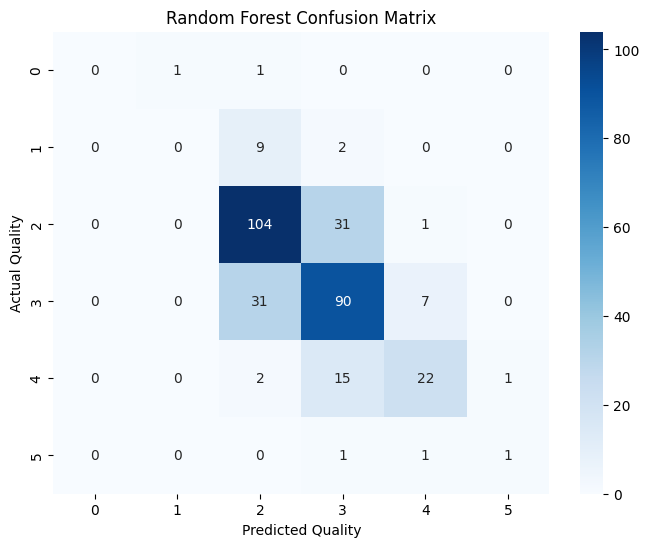

In [ ]:
cm = confusion_matrix(y_test, rf_prediction)
plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues')
plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted Quality')
plt.ylabel('Actual Quality')
plt.show()

#